# Unit 5 — companion notebook
Code for the worked examples in the [Unit 5 notes](https://elevien.github.io/math50_sandbox/unit5/).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import signal

rng = np.random.default_rng(0)

### Example: visualizing interactions

slope of E[Y|X1,X2=0] vs X1: 1.2
slope of E[Y|X1,X2=1] vs X1: 0.19999999999999996


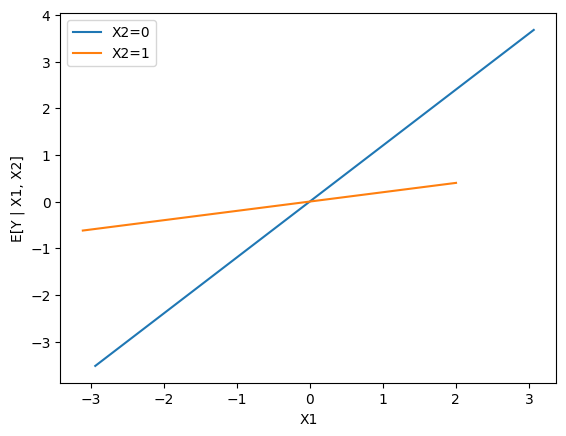

In [2]:
beta1, beta2, J = 1.2, 0.0, -1.0
X1 = rng.normal(size=300)
X2 = rng.binomial(1, 0.5, size=300)

print("slope of E[Y|X1,X2=0] vs X1:", beta1 + J * 0)
print("slope of E[Y|X1,X2=1] vs X1:", beta1 + J * 1)

for x2val in [0, 1]:
    mask = X2 == x2val
    xs = np.sort(X1[mask])
    plt.plot(xs, beta2 * x2val + (beta1 + J * x2val) * xs, label=f"X2={x2val}")
plt.xlabel("X1")
plt.ylabel("E[Y | X1, X2]")
plt.legend()
plt.show()

### Example: interaction in the test-score model

In [3]:
url = "https://raw.githubusercontent.com/avehtari/ROS-Examples/master/KidIQ/data/kidiq.csv"
df = pd.read_csv(url)
df["hs_iq"] = df["mom_hs"] * df["mom_iq"]

X = sm.add_constant(df[["mom_hs", "mom_iq", "hs_iq"]])
fit = sm.OLS(df["kid_score"], X).fit()
print(fit.summary())

                            OLS Regression Results                            
Dep. Variable:              kid_score   R-squared:                       0.230
Model:                            OLS   Adj. R-squared:                  0.225
Method:                 Least Squares   F-statistic:                     42.84
Date:                Thu, 27 Aug 2026   Prob (F-statistic):           3.07e-24
Time:                        12:34:54   Log-Likelihood:                -1867.5
No. Observations:                 434   AIC:                             3743.
Df Residuals:                     430   BIC:                             3759.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -11.4820     13.758     -0.835      0.4

### Example: residual plots

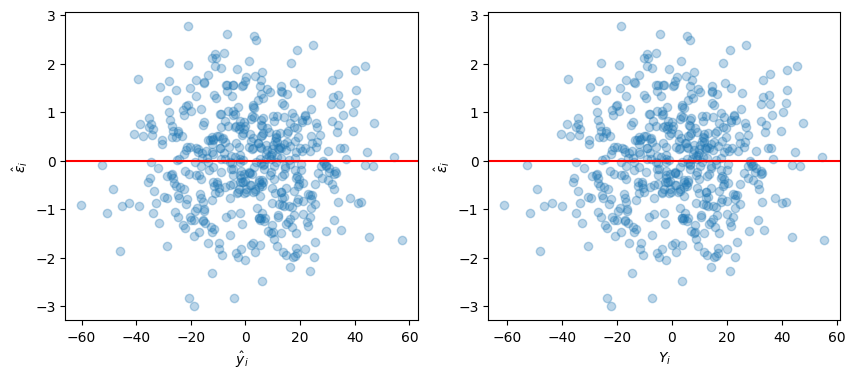

cov(resid, Y) = 1.0709088545368812  var(resid) = 1.0687670368279083


In [4]:
n = 500
beta0, beta1, beta2, sigma = 0, 0.2, 20, 1
X1 = rng.normal(size=n)
X2 = rng.normal(size=n)
Y = beta0 + beta1 * X1 + beta2 * X2 + rng.normal(scale=sigma, size=n)

X = sm.add_constant(np.column_stack([X1, X2]))
fit = sm.OLS(Y, X).fit()
resid, yhat = fit.resid, fit.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(yhat, resid, alpha=0.3)
axes[0].axhline(0, color="red")
axes[0].set_xlabel(r"$\hat y_i$"); axes[0].set_ylabel(r"$\hat\epsilon_i$")
axes[1].scatter(Y, resid, alpha=0.3)
axes[1].axhline(0, color="red")
axes[1].set_xlabel(r"$Y_i$"); axes[1].set_ylabel(r"$\hat\epsilon_i$")
plt.show()

print("cov(resid, Y) =", np.cov(resid, Y)[0, 1], " var(resid) =", resid.var())

### Example: simulating a nonlinear model

fitted: [1.00784705 2.02994107 2.96825437]  true: [1, 2, 3]


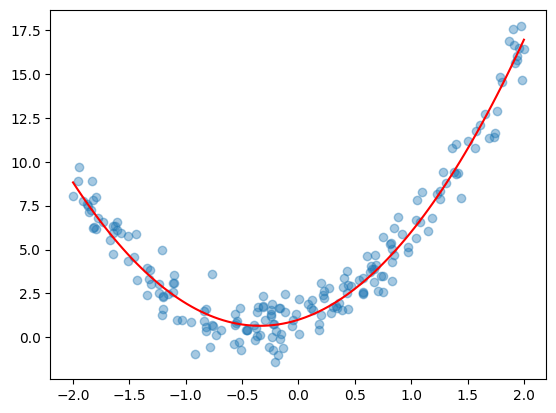

In [5]:
n = 200
beta0, beta1, beta2, sigma = 1, 2, 3, 1
X = rng.uniform(-2, 2, size=n)
Y = beta0 + beta1 * X + beta2 * X**2 + rng.normal(scale=sigma, size=n)

Xd = sm.add_constant(np.column_stack([X, X**2]))
fit = sm.OLS(Y, Xd).fit()
print("fitted:", fit.params, " true:", [beta0, beta1, beta2])

xs = np.linspace(-2, 2, 100)
plt.scatter(X, Y, alpha=0.4)
plt.plot(xs, fit.params[0] + fit.params[1] * xs + fit.params[2] * xs**2, color="red")
plt.show()

### Example: cross-validation on a polynomial model

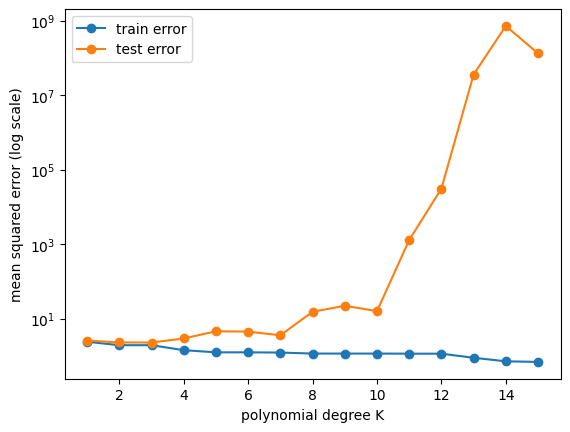

In [6]:
f_true = lambda x: 1 + 2 * x + 3 * x**2
n = 40
X = rng.uniform(-1, 1, size=n)
Y = f_true(X) + rng.normal(scale=1.5, size=n)

idx = rng.permutation(n)
train_idx, test_idx = idx[:25], idx[25:]

degrees = range(1, 16)
train_err, test_err = [], []
for K in degrees:
    A = np.vander(X, K + 1, increasing=True)
    Atr, Ate = A[train_idx], A[test_idx]
    Ytr, Yte = Y[train_idx], Y[test_idx]
    beta_hat, *_ = np.linalg.lstsq(Atr, Ytr, rcond=None)
    train_err.append(np.mean((Atr @ beta_hat - Ytr) ** 2))
    test_err.append(np.mean((Ate @ beta_hat - Yte) ** 2))

plt.plot(list(degrees), train_err, "o-", label="train error")
plt.plot(list(degrees), test_err, "o-", label="test error")
plt.yscale("log")
plt.xlabel("polynomial degree K")
plt.ylabel("mean squared error (log scale)")
plt.legend()
plt.show()

### Example: plotting bias and variance

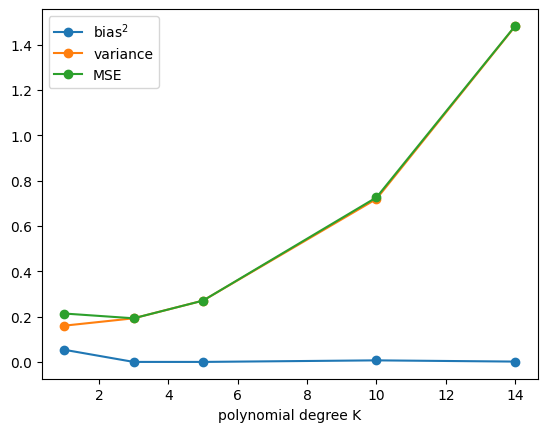

In [7]:
x0 = 0.5
n_datasets = 1000
K_list = [1, 3, 5, 10, 14]
phi0 = np.array([x0**k for k in range(max(K_list) + 1)])

biases, variances = [], []
for K in K_list:
    preds = []
    for _ in range(n_datasets):
        X = rng.uniform(-1, 1, size=n)
        Y = f_true(X) + rng.normal(scale=1.5, size=n)
        A = np.vander(X, K + 1, increasing=True)
        beta_hat, *_ = np.linalg.lstsq(A, Y, rcond=None)
        preds.append(phi0[:K + 1] @ beta_hat)
    preds = np.array(preds)
    biases.append(preds.mean() - f_true(x0))
    variances.append(preds.var())

plt.plot(K_list, np.array(biases) ** 2, "o-", label="bias$^2$")
plt.plot(K_list, variances, "o-", label="variance")
plt.plot(K_list, np.array(biases) ** 2 + np.array(variances), "o-", label="MSE")
plt.xlabel("polynomial degree K")
plt.legend()
plt.show()

### Example: sine series

In [8]:
L = 1.0
N = 200_000
X = rng.uniform(-L, L, size=N)

def phi(j, x):
    return np.sin(np.pi * x * j / L)

for j, k in [(1, 2), (2, 3), (1, 3)]:
    print(f"cov(phi_{j}, phi_{k}) ~ {np.mean(phi(j, X) * phi(k, X)):.4f}")

cov(phi_1, phi_2) ~ 0.0006
cov(phi_2, phi_3) ~ 0.0011
cov(phi_1, phi_3) ~ -0.0018


### Example: Fourier series in Python

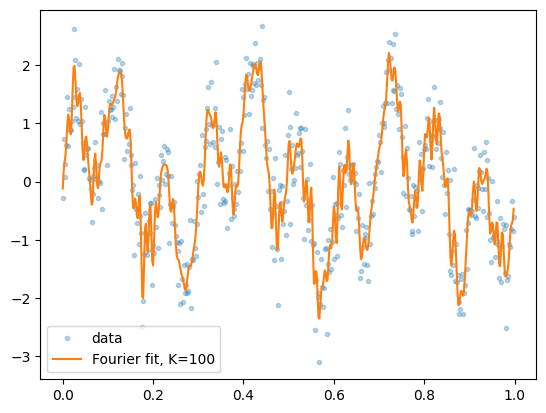

In [9]:
L = 1.0
N = 500
X = L * np.arange(N) / N  # evenly spaced on [0, L)
f_true_fourier = lambda x: np.sin(2 * np.pi * 3 * x / L) + np.sin(2 * np.pi * 10 * x / L)
sigma = 0.5
Y = f_true_fourier(X) + rng.normal(scale=sigma, size=N)

K = 100
cols = [np.ones(N)]
for k in range(1, K + 1):
    cols.append(np.sin(2 * np.pi * k * X / L))
    cols.append(np.cos(2 * np.pi * k * X / L))
A = np.column_stack(cols)
beta_hat, *_ = np.linalg.lstsq(A, Y, rcond=None)
fitted = A @ beta_hat

plt.plot(X, Y, ".", alpha=0.3, label="data")
plt.plot(X, fitted, label="Fourier fit, K=100")
plt.legend()
plt.show()

### Example: periodogram

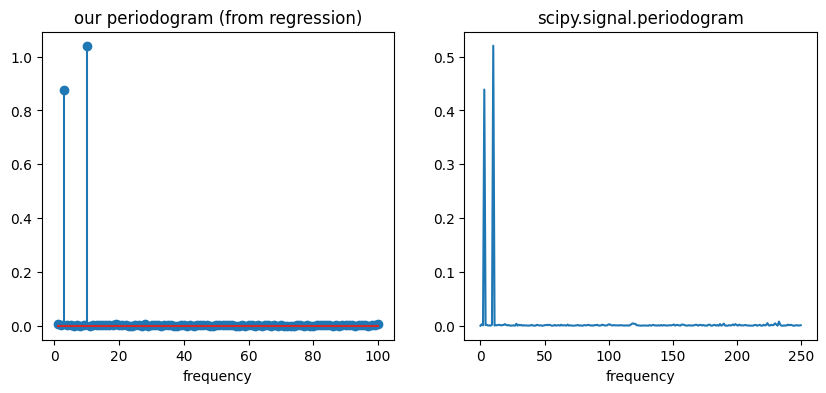

top frequencies (ours): [np.int64(3), np.int64(10)]


In [10]:
betas, alphas = beta_hat[1::2], beta_hat[2::2]
P_ours = betas**2 + alphas**2
freqs_ours = np.arange(1, K + 1)

f_scipy, P_scipy = signal.periodogram(Y, fs=N / L)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].stem(freqs_ours, P_ours)
axes[0].set_title("our periodogram (from regression)")
axes[1].plot(f_scipy, P_scipy)
axes[1].set_title("scipy.signal.periodogram")
for ax in axes:
    ax.set_xlabel("frequency")
plt.show()

top = np.argsort(P_ours)[-2:] + 1
print("top frequencies (ours):", sorted(top))